# 1. Project Introduction & Exploratory Objectives

This notebook initiates the first phase (**Phase 01: Exploratory Data Analysis**) of the Student Mental Health Prediction project.

### Core Objectives:
1. **Structural Audit:** Investigate dataset schema, dimensional properties, data types, and primary key integrity.
2. **Distributional Profiling:** Assess central tendency, spread, skewness, and modality across all numerical indicators.
3. **Target Analysis:** Quantify class balance and prevalence for the primary outcome variable (`Mental_Health_Risk`).
4. **Pattern & Correlation Discovery:** Uncover bivariate interactions, collinearity patterns, and protective vs. risk factors.
5. **Data Quality Inventory:** Detect missing values, empirical outliers, and logical cross-feature anomalies to establish a rigorous, actionable preprocessing specification for **Phase 02**.

> **Methodological Note:** This stage is strictly exploratory and non-destructive. No observations are dropped, transformed, or imputed in this notebook to maintain baseline data integrity. Observed correlations represent statistical associations, not clinical diagnoses or causal relationships.

# 2. Dataset Overview & Architectural Scope

The dataset comprises **2,000 unique student records** described by **17 variables**:
- **Identifier (1):** `Student_ID` (unique alphanumeric primary key).
- **Academic Profile (4):** `Year_of_Study`, `Study_Hours_Per_Week`, `GPA`, `Attendance_Rate`.
- **Lifestyle & Digital Behavior (4):** `Sleep_Hours`, `Social_Media_Hours`, `Screen_Time_Hours`, `Diet_Quality`, `Physical_Activity`.
- **Psychosocial Context (3):** `Financial_Stress`, `Family_Support`, `Previous_Mental_Health_History`.
- **Demographics (2):** `Age`, `Gender`, `Part_Time_Job`.
- **Target Variable (1):** `Mental_Health_Risk` (Categorical: `Low`, `Medium`, `High`).

The following setup cells import analytical libraries (`pandas`, `matplotlib`, `seaborn`, `pathlib`) and configure relative directories for inputs and visualization exports.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
root = Path.cwd().parent

In [ ]:
plot_path = root / "outputs" / "EDA_plots"
DATA_PATH = root / "data" / "student_mental_health.csv"

# 3. Data Ingestion, Structural Inspection & Schema Validation

### Plan & Objectives:
- Load the raw dataset from `data/student_mental_health.csv` without modifying values.
- Verify dimensional row/column shape.
- Inspect the first 5 records (`head()`) to understand value formatting.
- Examine non-null counts, storage dtypes (`info()`, `dtypes`), and verify the complete column catalog.
- Compute parametric descriptive statistics across all numerical metrics (`describe()`).

In [ ]:
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df_raw.shape}")

Dataset shape: (2000, 17)


In [5]:
df_raw.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [6]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [7]:
print("===== TYPES DES COLONNES =====")
print(df_raw.dtypes)

===== TYPES DES COLONNES =====
Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object


In [8]:
df_raw.columns.tolist()

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [9]:
df_raw.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


# 4. Descriptive Statistics & Central Tendency Analysis

### Output Findings & Analysis:
- **Sample Scale:** Total population of $N = 2,000$ students with a memory footprint of ~265.8 KB.
- **Age:** Ranges from 17 to 29 years ($\mu = 21.13, \sigma = 2.14, \text{median} = 21.0$). Senior undergraduate/mature students (ages 28–29) occupy the upper tail.
- **Sleep Hours:** Averages 6.76 hours/night ($\sigma = 1.13$), spanning severe deprivation (3.30h) to surplus sleep (10.0h).
- **Study Hours Per Week:** Averages 20.00 hours/week ($\sigma = 5.72$, min: 2.40h, max: 38.30h).
- **Academic Performance (GPA):** Centered at $\mu = 2.56$ ($\sigma = 0.34$, min: 1.50, max: 3.66), showing near-perfect symmetry with a median of 2.56.
- **Digital Exposure:** Daily social media averages 6.01 hours (max: 10.0h), while daily total screen time averages 8.55 hours (max: 14.0h).
- **Psychosocial Scales:** `Financial_Stress` ($\mu = 5.96$) and `Family_Support` ($\mu = 6.52$) span wide ranges on 10-point scales.
- **Attendance Rate:** High baseline ($\mu = 85.08\%, \sigma = 7.22\%$), dropping to a minimum of 54.40%.

---

# 5. Data Integrity: Duplicates & Missing Values Verification

### Plan & Objectives:
- Check for completely duplicated rows and duplicate `Student_ID` keys.
- Quantify exact missing value counts across all features.
- Evaluate frequency distributions across discrete and categorical features to assess representation.

In [10]:
print("Duplicate rows:", df_raw.duplicated().sum())

print(
    "Duplicate Student IDs:",
    df_raw["Student_ID"].duplicated().sum()
)

print(
    "Unique Student IDs:",
    df_raw["Student_ID"].nunique()
)

Duplicate rows: 0
Duplicate Student IDs: 0
Unique Student IDs: 2000


In [11]:
print("\n===== VALEURS MANQUANTES =====")
print(df_raw.isnull().sum())


===== VALEURS MANQUANTES =====
Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64


In [12]:
print("===== FREQUENCES =====")

for col in [
    "Age",
    "Gender",
    "Year_of_Study",
    "Sleep_Hours",
    "Study_Hours_Per_Week",
    "GPA",
    "Social_Media_Hours",
    "Screen_Time_Hours",
    "Physical_Activity",
    "Financial_Stress",
    "Family_Support",
    "Attendance_Rate",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History",
    "Mental_Health_Risk",
]:
    print(f"\n--- {col} ---")
    print(df_raw[col].value_counts())

===== FREQUENCES =====

--- Age ---
Age
21    380
22    342
20    322
23    233
19    228
24    142
18    133
17     93
25     76
26     37
27     10
28      3
29      1
Name: count, dtype: int64

--- Gender ---
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

--- Year_of_Study ---
Year_of_Study
1    509
2    500
3    426
4    352
5    213
Name: count, dtype: int64

--- Sleep_Hours ---
Sleep_Hours
6.8    83
6.6    77
6.4    75
6.1    73
6.9    70
       ..
9.8     2
9.3     2
3.7     1
3.6     1
3.3     1
Name: count, Length: 66, dtype: int64

--- Study_Hours_Per_Week ---
Study_Hours_Per_Week
21.6    19
16.2    19
19.2    19
17.1    19
19.6    18
        ..
9.5      1
7.9      1
33.1     1
4.9      1
8.9      1
Name: count, Length: 284, dtype: int64

--- GPA ---
GPA
2.47    31
2.66    31
2.64    30
2.70    29
2.63    27
        ..
3.06     1
1.60     1
3.39     1
1.81     1
1.74     1
Name: count, Length: 182, dtype: int64

--- Social_Media_Hours 

# 6. Data Integrity & Univariate Frequency Findings

### Output Analysis & Key Insights:
1. **Zero Redundancy:** 
   - Full row duplicates: **0**.
   - Duplicate `Student_ID` entries: **0** ($2,000$ unique IDs). `Student_ID` is a true primary key and must be dropped during modeling to avoid target leakage.
2. **Missingness Quantification (419 Total Missing Cells):**
   - Missing data affects **7 distinct features**, all with missingness rates below 5%:
     - `Financial_Stress`: 91 missing (4.55%)
     - `Diet_Quality`: 69 missing (3.45%)
     - `Sleep_Hours`: 62 missing (3.10%)
     - `Social_Media_Hours`: 58 missing (2.90%)
     - `Family_Support`: 54 missing (2.70%)
     - `Attendance_Rate`: 47 missing (2.35%)
     - `GPA`: 38 missing (1.90%)
   - Crucially, the target `Mental_Health_Risk` has **0 missing values** (100% complete).
3. **Category Representation:**
   - `Gender`: Female (971, 48.6%), Male (932, 46.6%), Non-binary (97, 4.9%).
   - `Physical_Activity`: Moderate (906), Low (679), High (415).
   - `Part_Time_Job`: No (1,289, 64.5%), Yes (711, 35.5%).
   - `Diet_Quality`: Average (860), Poor (587), Good (484).
   - `Previous_Mental_Health_History`: No (1,408, 70.4%), Yes (592, 29.6%).
   - No category suffers from severe sparsity, confirming suitability for one-hot and ordinal encoding in Phase 02.

In [13]:
sns.set_theme(style="whitegrid", palette="Set2")

RISK_ORDER = ["Low", "Medium", "High"]

numeric_cols = df_raw.select_dtypes(include="number").columns.tolist()

categorical_cols = [
    "Gender",
    "Physical_Activity",
    "Part_Time_Job",
    "Diet_Quality",
    "Previous_Mental_Health_History"
]

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Categorical columns: ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History']


# 7. Target Variable Distribution (`Mental_Health_Risk`)

### Plan & Objectives:
- Plot the discrete frequency counts of the target variable `Mental_Health_Risk` ordered canonically (`Low` → `Medium` → `High`).
- Compute normalized class percentages to verify balance.

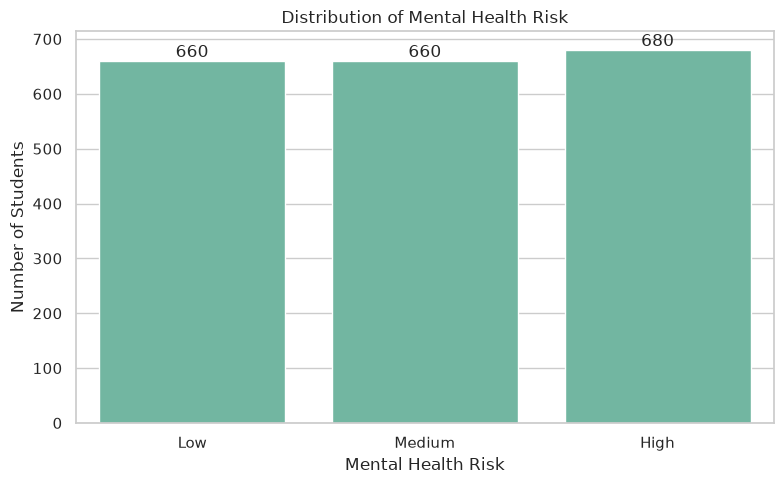

In [14]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_raw,
    x="Mental_Health_Risk",
    order=RISK_ORDER
)

plt.title("Distribution of Mental Health Risk")
plt.xlabel("Mental Health Risk")
plt.ylabel("Number of Students")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(plot_path / "01_Target_distribution.png")
plt.show()

In [15]:
risk_percentage = (
    df_raw["Mental_Health_Risk"]
    .value_counts(normalize=True)
    .reindex(RISK_ORDER) * 100
)

print(risk_percentage.round(2))

Mental_Health_Risk
Low       33.0
Medium    33.0
High      34.0
Name: proportion, dtype: float64


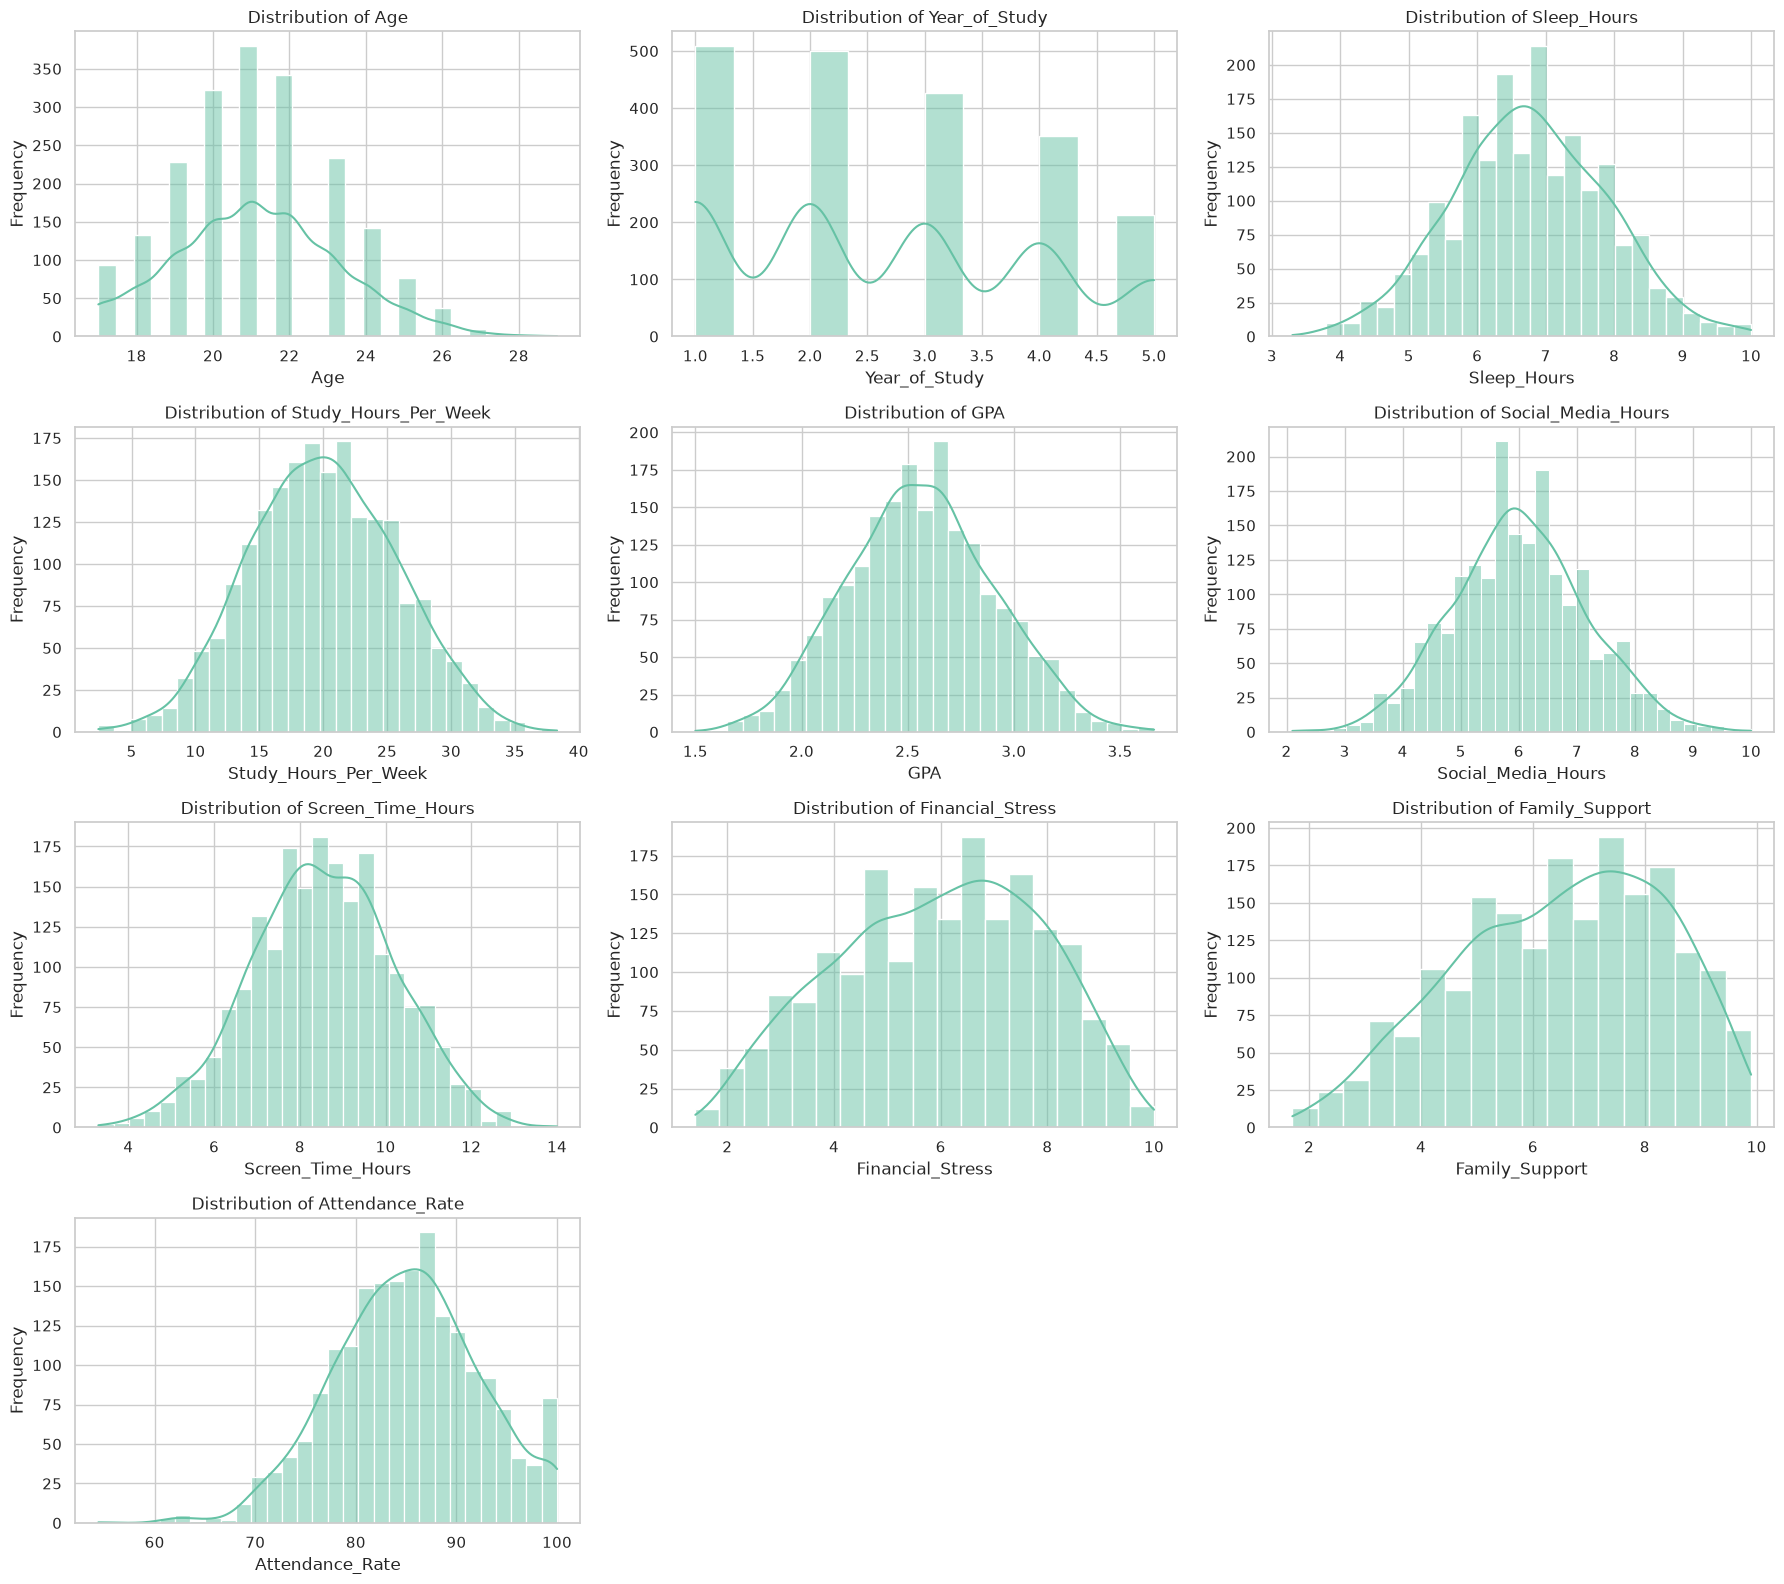

In [16]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(18, 16)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):

    sns.histplot(
        data=df_raw,
        x=col,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig(plot_path / "02_Num_Feats_distribution.png")
plt.show()

In [17]:
skewness = df_raw[numeric_cols].skew().sort_values()

display(skewness.to_frame("Skewness"))

,Skewness
Family_Support,-0.304270
Financial_Stress,-0.168759
Attendance_Rate,-0.116483
Screen_Time_Hours,-0.044073
Study_Hours_Per_Week,0.039271
Sleep_Hours,0.051094
GPA,0.087445
Social_Media_Hours,0.092598
Age,0.200876
Year_of_Study,0.314226


# 8. Target Balance Findings & Numerical Distribution Analysis

### Target Distribution Output Analysis:
- **Class Proportions:** Low: **33.0%** (660), Medium: **33.0%** (660), High: **34.0%** (680).
- **Significance:** The target displays virtually optimal 1:1:1 balance. Downstream classifiers will not require artificial resampling (e.g., SMOTE) or severe class-weight penalties. Standard multi-class metrics (Accuracy, Macro-F1, ROC-AUC) will provide reliable evaluation.

---

### Numerical Features & Skewness Analysis:
- **Empirical Shapes:** Visual inspection of KDE curves confirms unimodal distributions across all 10 numerical features.
- **Skewness Coefficients:**
  - All features reside strictly within the $[-0.5, +0.5]$ threshold:
    - `Family_Support`: -0.304 | `Financial_Stress`: -0.169 | `Attendance_Rate`: -0.116
    - `Screen_Time_Hours`: -0.044 | `Study_Hours_Per_Week`: +0.039 | `Sleep_Hours`: +0.051
    - `GPA`: +0.087 | `Social_Media_Hours`: +0.093 | `Age`: +0.201 | `Year_of_Study`: +0.314
- **Implication:** Features exhibit near-Gaussian symmetry. Standard linear scaling (StandardScaler or MinMaxScaler) is appropriate without requiring heavy non-linear power transformations (e.g., Box-Cox or Log).

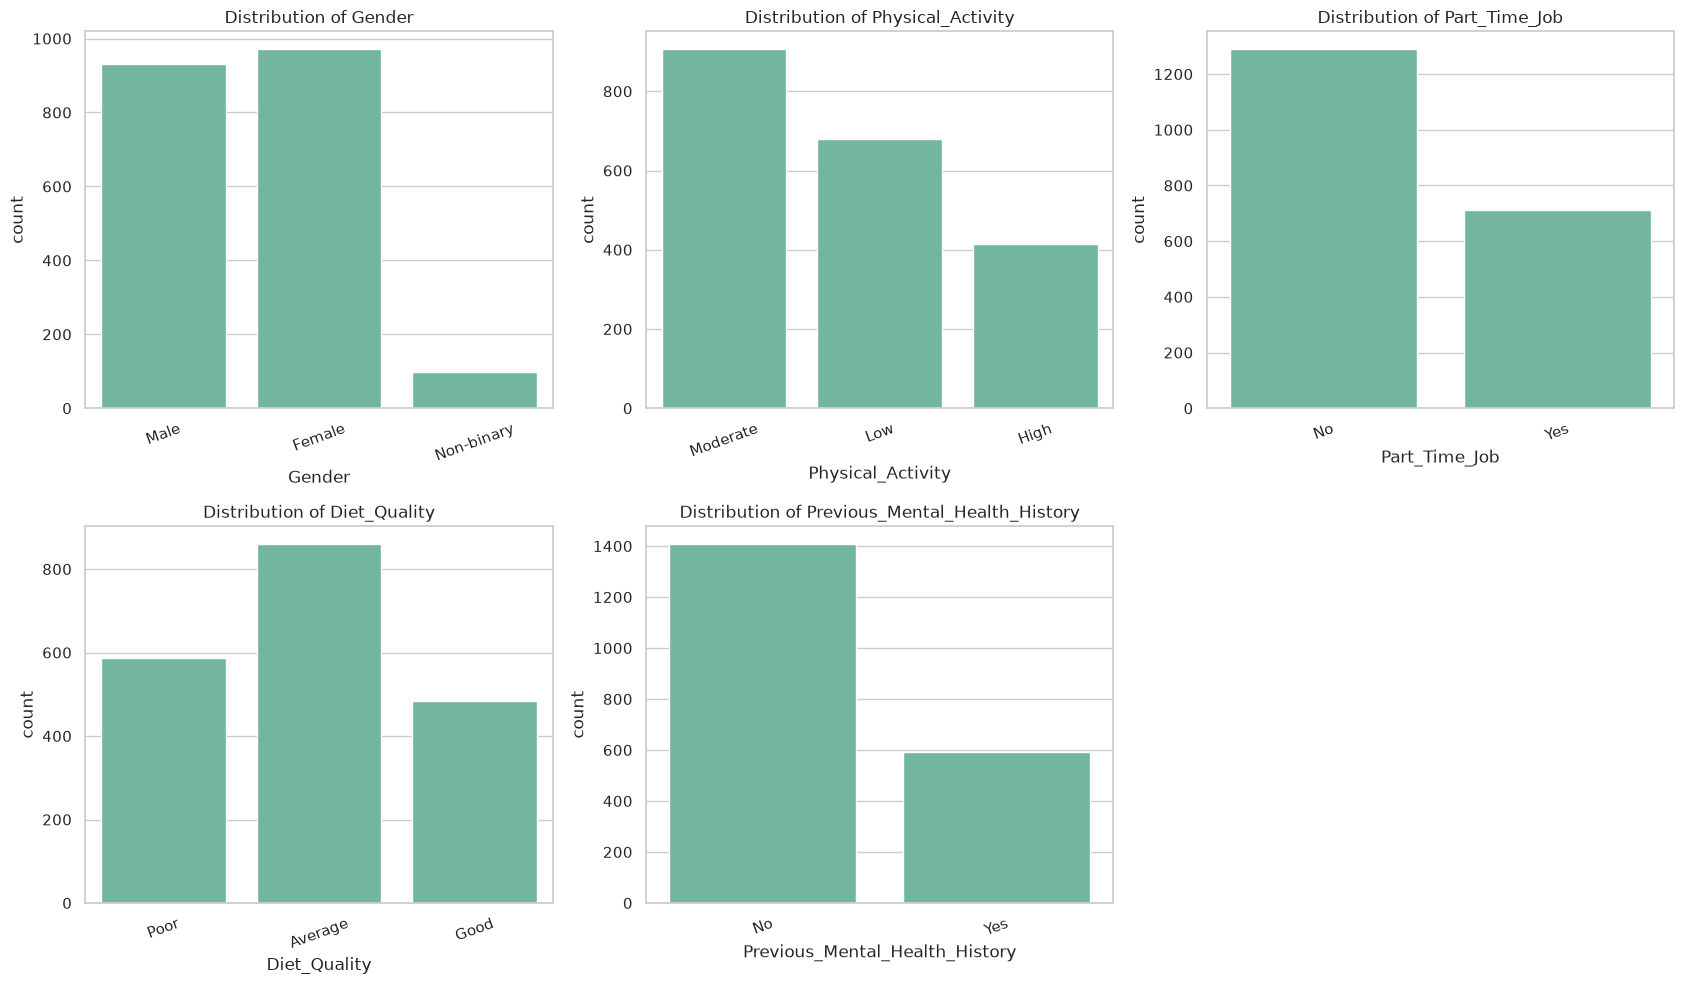

In [18]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):

    sns.countplot(
        data=df_raw,
        x=col,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis="x", rotation=20)

axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig(plot_path / "03_Cat_Feats_distribution.png")
plt.show()

# 9. Categorical Features Distribution Analysis

### Output Findings:
- **Demographic Balance:** Balanced gender split between Female (48.6%) and Male (46.6%), with meaningful Non-binary representation (4.9%).
- **Lifestyle Behavior:** Physical activity shows a natural gradient (Moderate > Low > High). Diet quality modal class is Average (43.0%), with Poor (29.4%) and Good (24.2%) representing substantial sub-populations.
- **Occupational & Clinical Context:** Over a third of students balance part-time employment (35.5%), and nearly 30% report a prior history of mental health challenges.
- **Preprocessing Handoff:** Nominal columns (`Gender`, `Part_Time_Job`, `Previous_Mental_Health_History`) will be mapped via one-hot encoding, while ordinal variables (`Physical_Activity`, `Diet_Quality`) can support integer rank mapping in Phase 02.

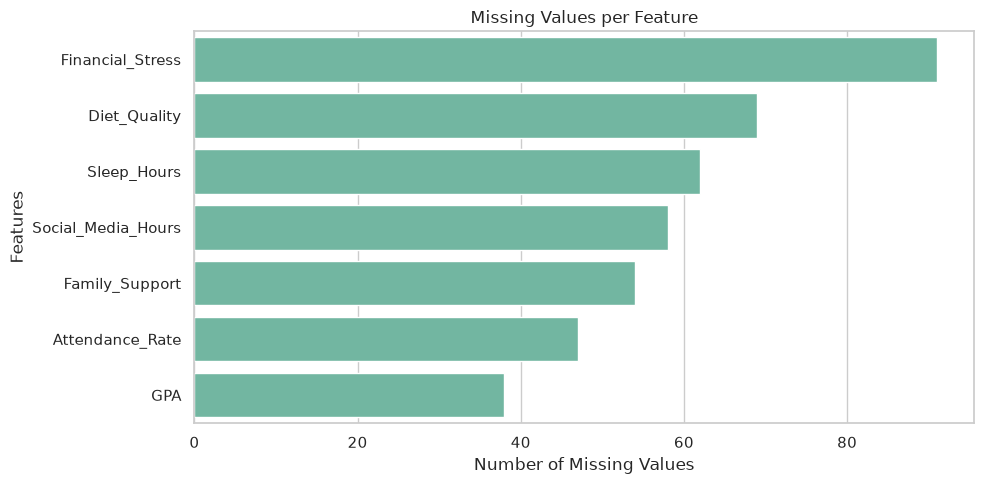

In [19]:
missing = df_raw.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing.values,
    y=missing.index
)

plt.title("Missing Values per Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Features")

plt.tight_layout()
plt.savefig(plot_path / "04_Missing_Values.png")
plt.show()

# 10. Missing Values Profile & Preprocessing Strategy

### Output Findings:
- Horizontal bar chart visualizes the 7 affected variables sorted by volume.
- Maximum missingness is bounded at 4.55% (`Financial_Stress`), while GPA has only 1.90% missingness.
- Total missingness accounts for 419 entries across the dataset.

### Action Plan for Phase 02 Preprocessing:
1. **Numerical Imputation:** Median imputation grouped by academic year or target risk is recommended due to robustness against extreme values.
2. **Categorical Imputation:** `Diet_Quality` (69 missing) will be imputed using the mode ('Average') or a dedicated 'Missing' level to preserve missingness signal.
3. **Avoid Deletion:** Complete case analysis (listwise deletion) would unnecessarily drop ~15-20% of the sample; imputation is strictly preferred.

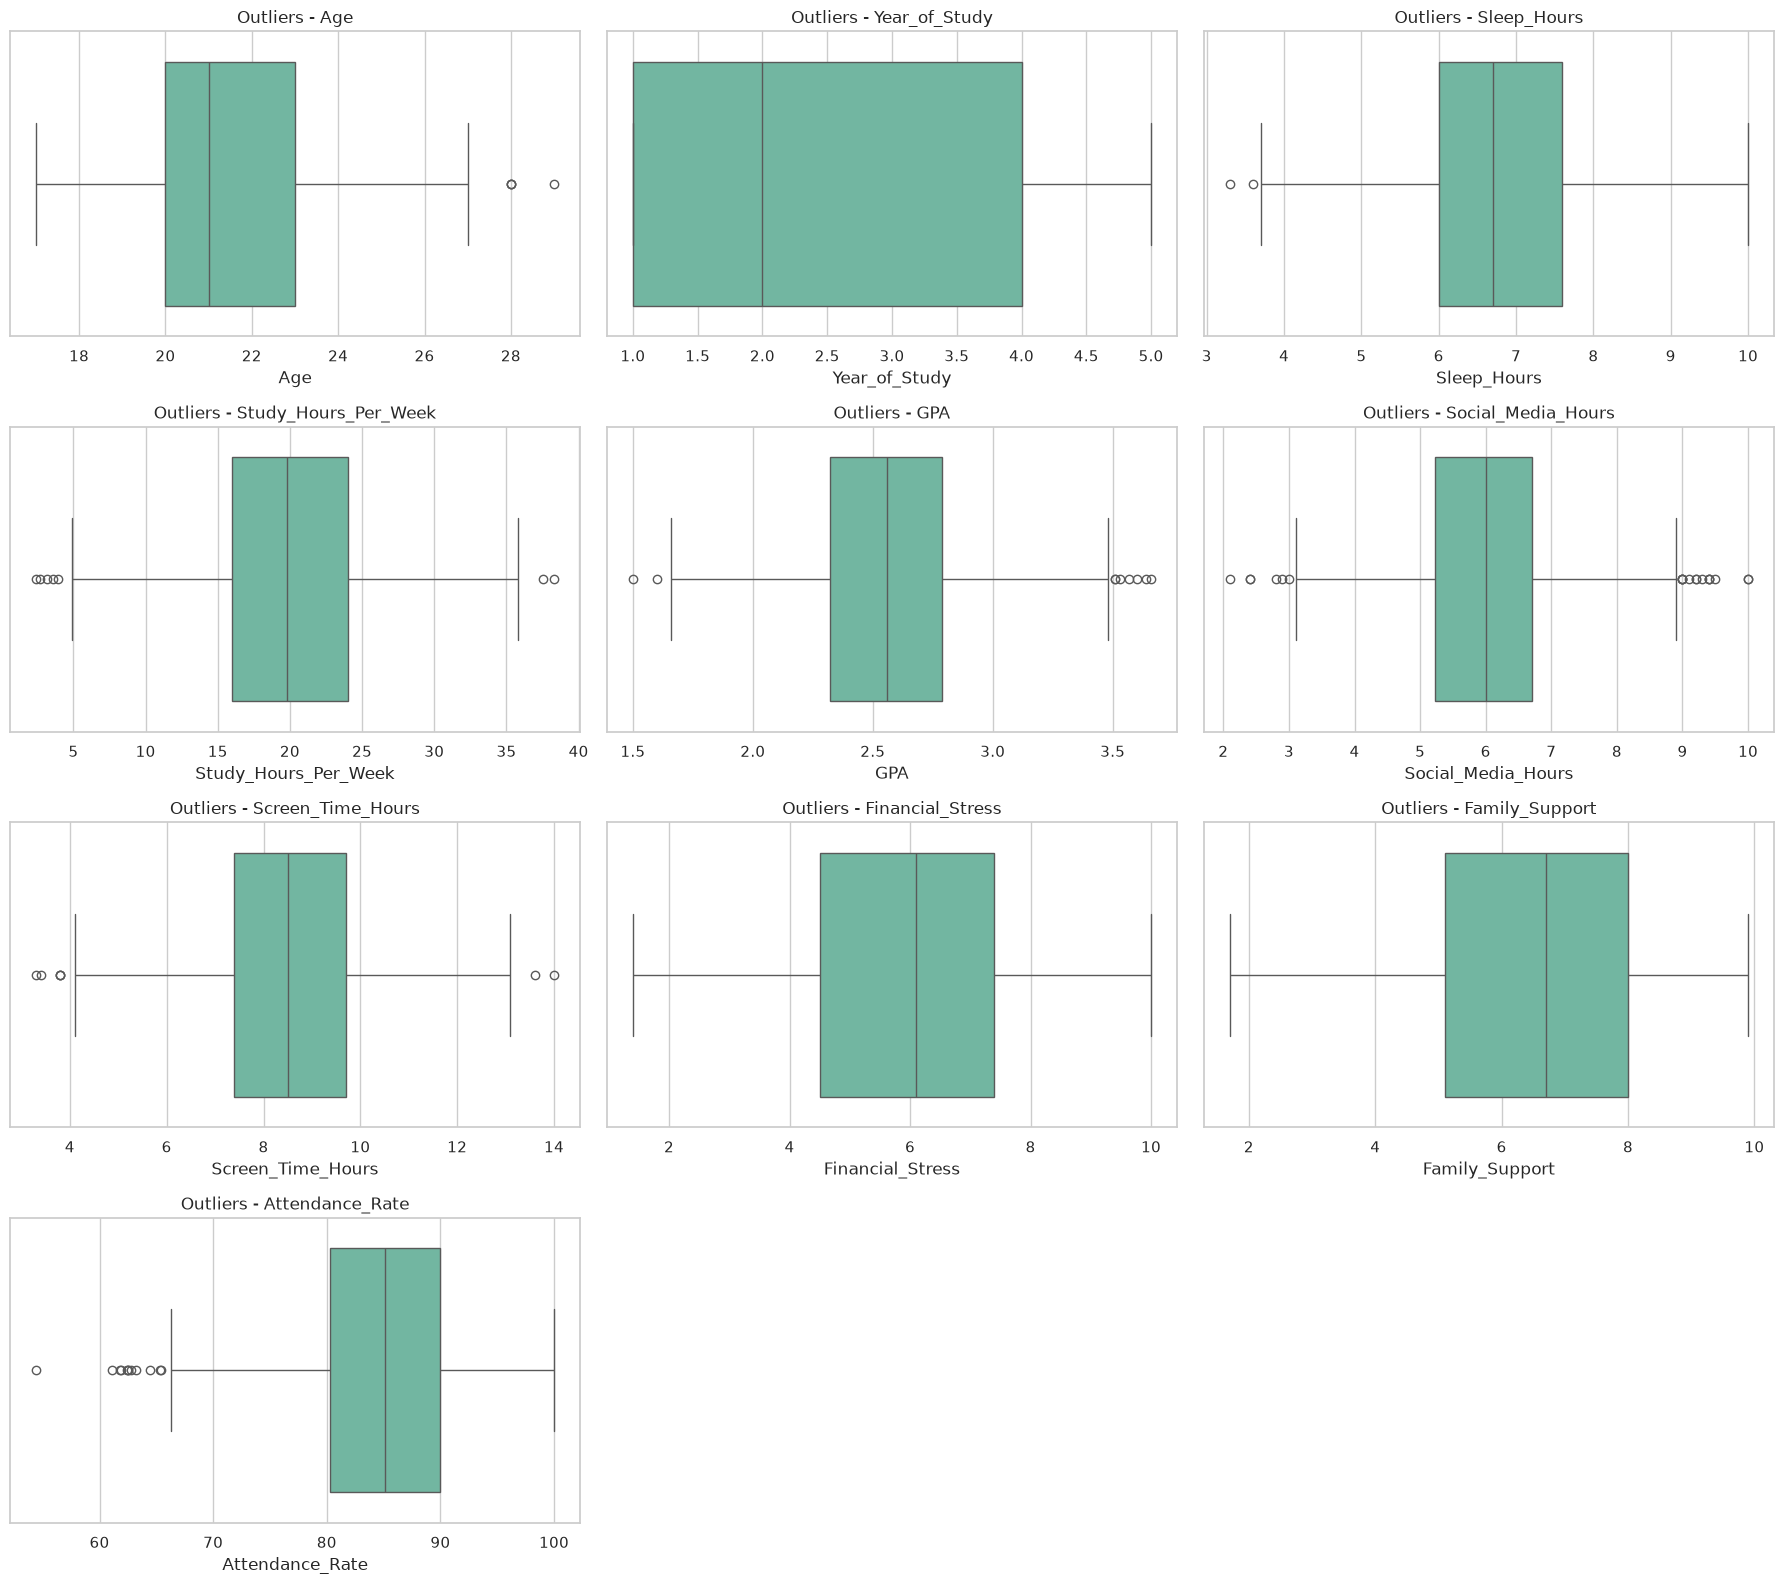

In [20]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(18, 16)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):

    sns.boxplot(
        data=df_raw,
        x=col,
        ax=axes[i]
    )

    axes[i].set_title(f"Outliers - {col}")

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig(plot_path / "05_Outliers_exploration.png")
plt.show()

# 11. Outlier Exploration & Statistical IQR Audit

### Plan & Objectives:
- Visually evaluate distribution tails using standardized boxplots across all numerical features.
- Execute an empirical Tukey Interquartile Range (IQR) detection algorithm:
  $$\text{IQR} = Q_3 - Q_1, \quad \text{Lower} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper} = Q_3 + 1.5 \times \text{IQR}$$
- Isolate and catalogue all observations exceeding these statistical thresholds into `df_outliers`.

In [21]:
outliers_list = []

for col in numeric_cols:

    Q1 = df_raw[col].quantile(0.25)
    Q3 = df_raw[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_raw[
        (df_raw[col] < lower_bound) |
        (df_raw[col] > upper_bound)
    ].copy()

    outliers["Outlier_Feature"] = col

    outliers_list.append(outliers)

df_outliers = pd.concat(outliers_list, ignore_index=True)

display(df_outliers)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk,Outlier_Feature
0,STU0210,29,Female,4,6.5,22.1,3.02,7.5,7.3,Moderate,7.8,6.9,90.4,Yes,NaN,No,Low,Age
1,STU0479,28,Female,2,9.1,13.6,2.52,6.6,8.5,Moderate,9.1,5.2,93.2,No,Poor,No,Medium,Age
2,STU1616,28,Male,2,5.5,20.6,2.91,6.7,8.2,Moderate,6.5,7.9,84.0,No,Poor,No,High,Age
3,STU1958,28,Male,4,6.3,27.6,2.92,4.6,6.3,Moderate,7.8,7.8,88.0,No,Good,No,Low,Age
4,STU0750,18,Male,3,3.6,19.9,3.05,4.2,6.2,Low,NaN,3.7,82.5,Yes,Average,No,High,Sleep_Hours
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,STU1250,18,Male,5,7.1,20.2,2.38,NaN,6.1,High,3.9,8.8,65.3,No,Poor,No,Low,Attendance_Rate
57,STU1274,20,Male,2,3.9,17.7,2.61,7.8,9.4,Low,7.5,8.8,54.4,No,Average,No,High,Attendance_Rate
58,STU1408,24,Female,3,7.6,21.1,2.23,5.5,7.7,Low,7.8,6.4,61.8,No,Good,No,Medium,Attendance_Rate
59,STU1646,22,Female,5,8.6,29.5,3.00,5.1,7.6,High,3.0,5.7,64.4,No,Average,No,Low,Attendance_Rate


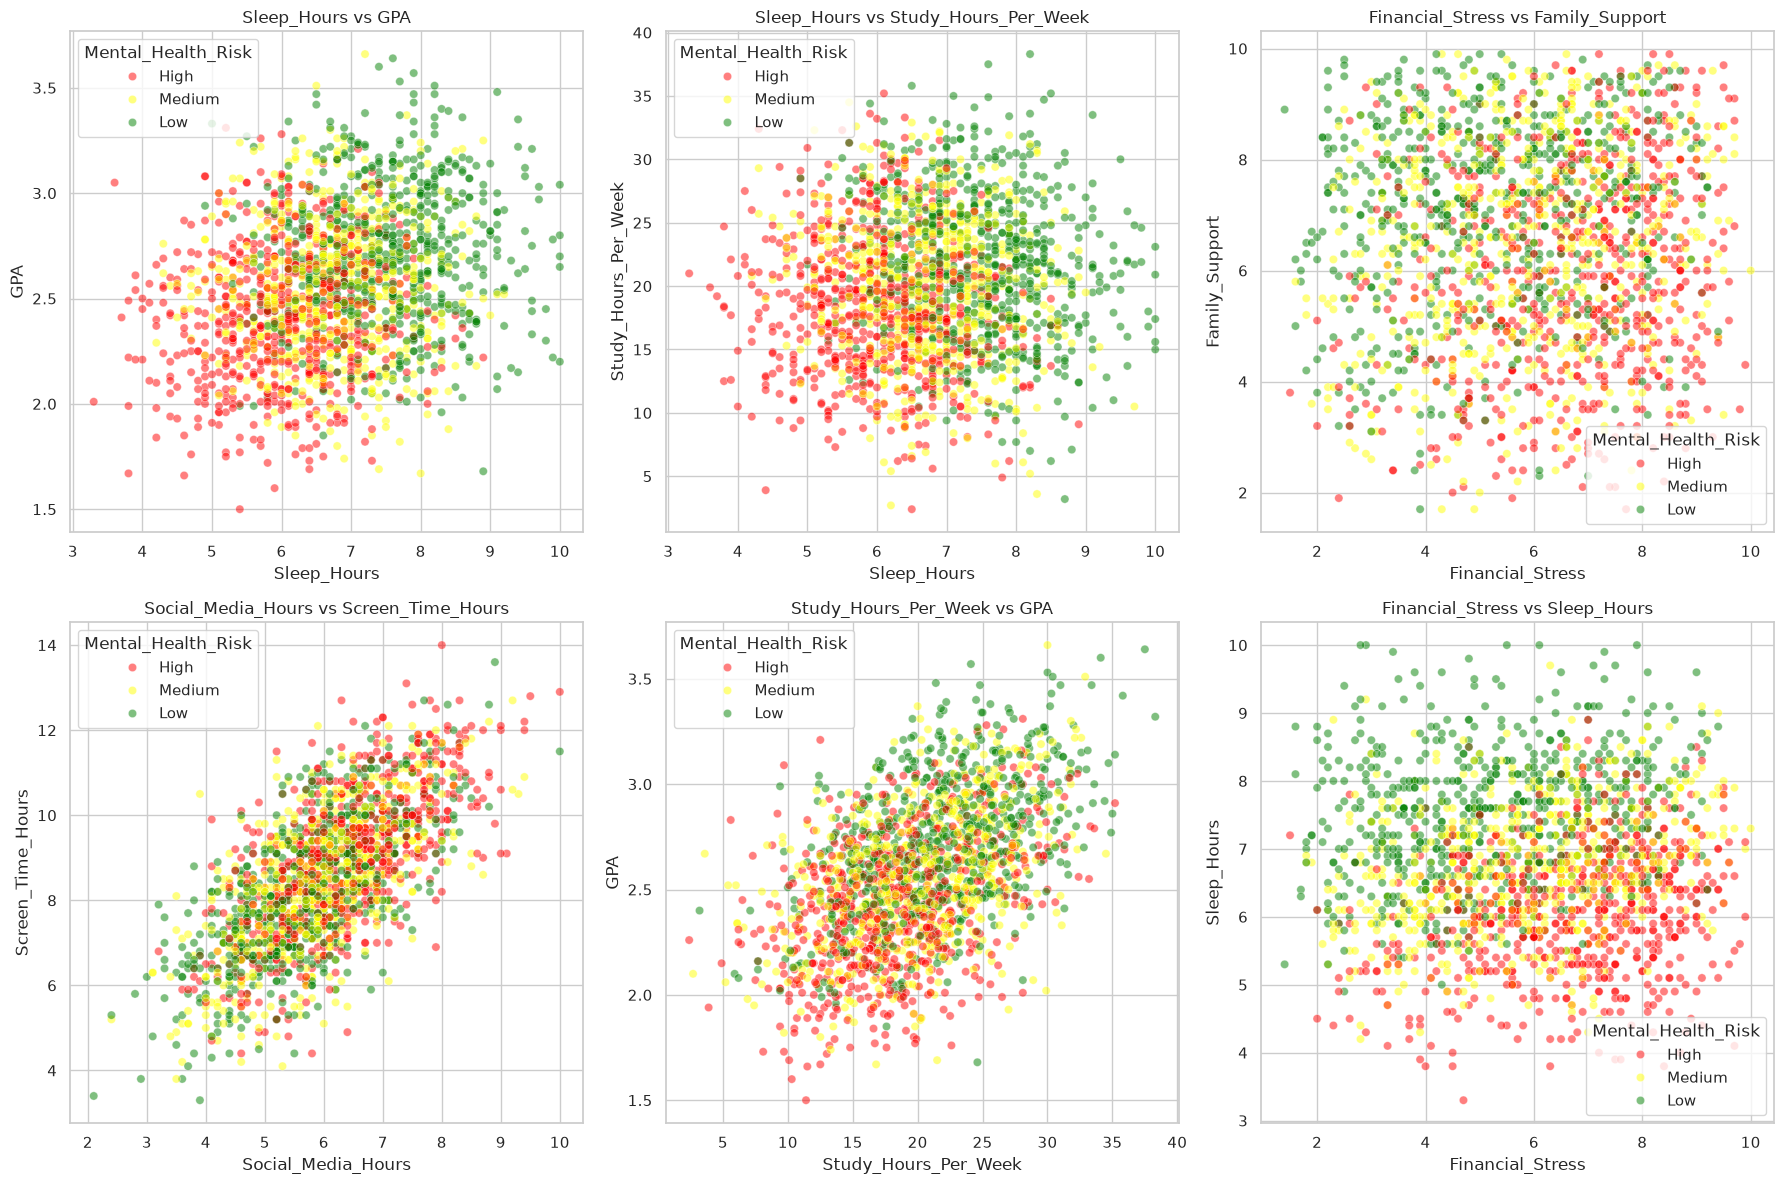

In [22]:

pairs = [
    ("Sleep_Hours", "GPA"),
    ("Sleep_Hours", "Study_Hours_Per_Week"),
    ("Financial_Stress", "Family_Support"),
    ("Social_Media_Hours", "Screen_Time_Hours"),
    ("Study_Hours_Per_Week", "GPA"),
    ("Financial_Stress", "Sleep_Hours")
]

risk_palette = {
    "Low": "green",
    "Medium": "yellow",
    "High": "red"
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

axes = axes.flatten()

for i, (x_col, y_col) in enumerate(pairs):

    sns.scatterplot(
        data=df_raw,
        x=x_col,
        y=y_col,
        hue="Mental_Health_Risk",
        alpha=0.5,
        palette=risk_palette,
        ax=axes[i]
    )

    axes[i].set_title(f"{x_col} vs {y_col}")

plt.tight_layout()
plt.savefig(plot_path / "06_Relation_COLvsCOL.png")
plt.show()


# 12. Outlier Audit Findings & Bivariate Interaction Analysis

### Outlier Detection Findings:
- Exactly **61 outlier instances** were detected across all 10 numerical features (~3.05% of entries).
- **Key Outlier Features:**
  - `Age`: 4 records with ages 28 and 29 (non-traditional students).
  - `Sleep_Hours`: Low-end outliers ranging between 3.3 and 3.9 hours/night.
  - `Study_Hours_Per_Week`: Upper-tail students reporting > 36 hours/week.
  - `Attendance_Rate`: Low-end outliers with attendance between 54.4% and 65.3%.
- **Recommendation for Phase 02:** These values reflect genuine human behavior within university populations rather than sensor or transcription errors. Observations should be **retained** and handled using robust scalers (`RobustScaler`) or percentile capping (Winsorization at 1st/99th percentiles) rather than row exclusion.

---

### Bivariate Scatter Plot Findings (`06_Relation_COLvsCOL.png`):
- **`Sleep_Hours` vs. `GPA`:** Pronounced risk clustering: High-risk students (red) congregate in the low sleep (< 6.5h) and lower GPA (< 2.5) quadrant, whereas Low-risk students (green) cluster at higher sleep (> 7h) and higher GPA (> 2.7).
- **`Financial_Stress` vs. `Family_Support`:** Severe financial stress combined with low family support shows strong separation for High Mental Health Risk.
- **`Social_Media_Hours` vs. `Screen_Time_Hours`:** Strong co-linearity; high usage correlates with elevated risk density.

In [23]:
mappings = {
    "Mental_Health_Risk": {
        "Low": 0, "Medium": 1, "High": 2
    },
    "Physical_Activity": {
        "Low": 0, "Moderate": 1, "High": 2
    },
    "Diet_Quality": {
        "Poor": 0, "Average": 1, "Good": 2
    }
}

df_correlation = df_raw.copy()

for col, mapping in mappings.items():
    df_correlation[col] = df_correlation[col].map(mapping)

df_correlation = pd.get_dummies(
    df_correlation,
    columns=[
        "Gender",
        "Part_Time_Job",
        "Previous_Mental_Health_History"
    ],
    dtype=int
)

df_numeric = df_correlation.select_dtypes(include="number")

correlation = df_numeric.drop(
    columns=["Student_ID"],
    errors="ignore"
).corr()

df_correlation.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Student_ID                          2000 non-null   str    
 1   Age                                 2000 non-null   int64  
 2   Year_of_Study                       2000 non-null   int64  
 3   Sleep_Hours                         1938 non-null   float64
 4   Study_Hours_Per_Week                2000 non-null   float64
 5   GPA                                 1962 non-null   float64
 6   Social_Media_Hours                  1942 non-null   float64
 7   Screen_Time_Hours                   2000 non-null   float64
 8   Physical_Activity                   2000 non-null   int64  
 9   Financial_Stress                    1909 non-null   float64
 10  Family_Support                      1946 non-null   float64
 11  Attendance_Rate                     1953 non-null   fl

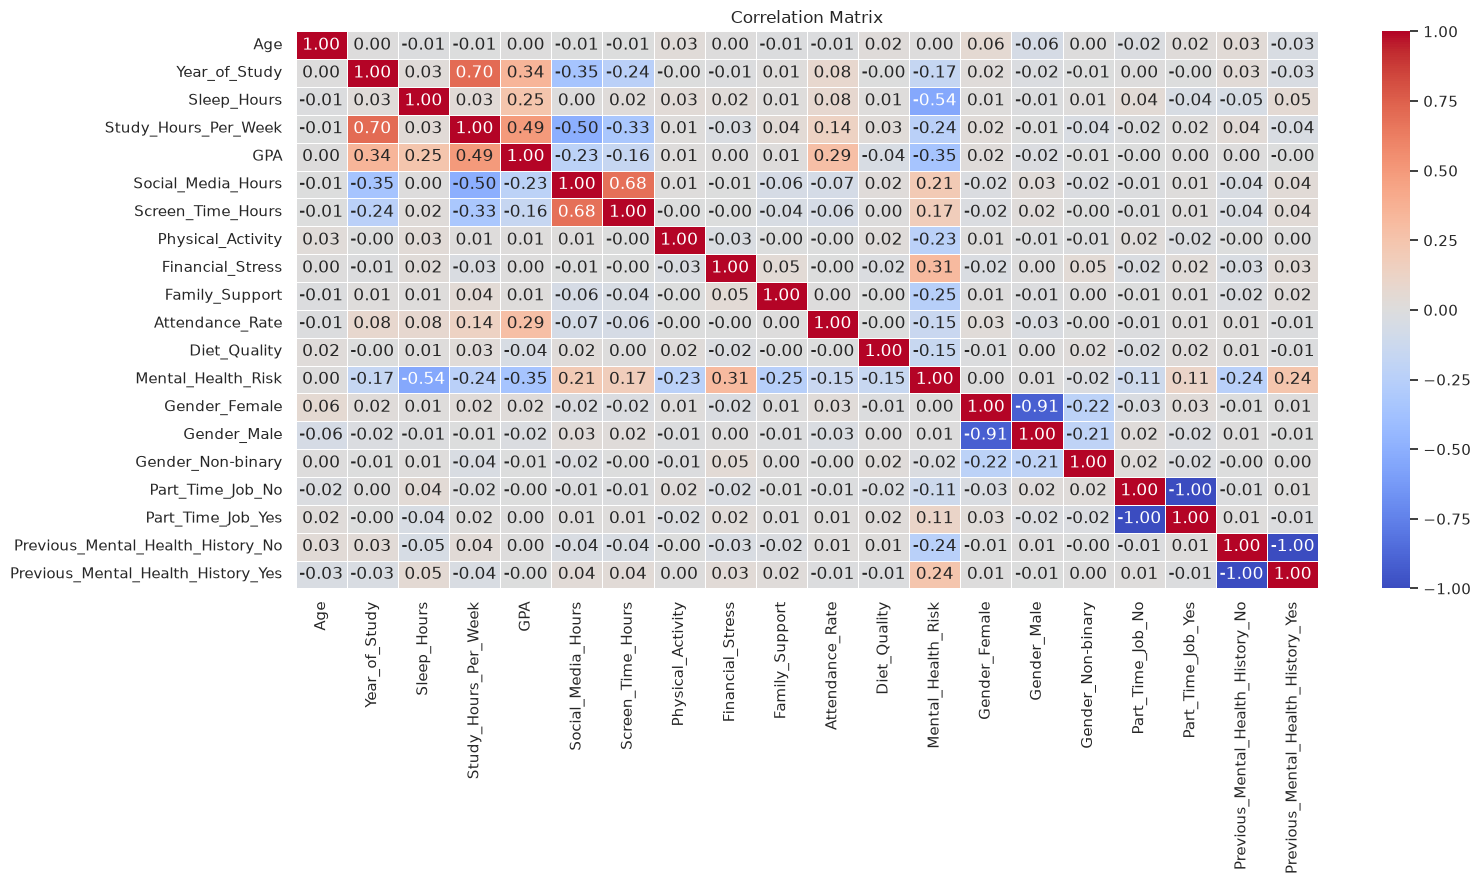

In [24]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.savefig(plot_path / "07_Correlation_Matrix.png")

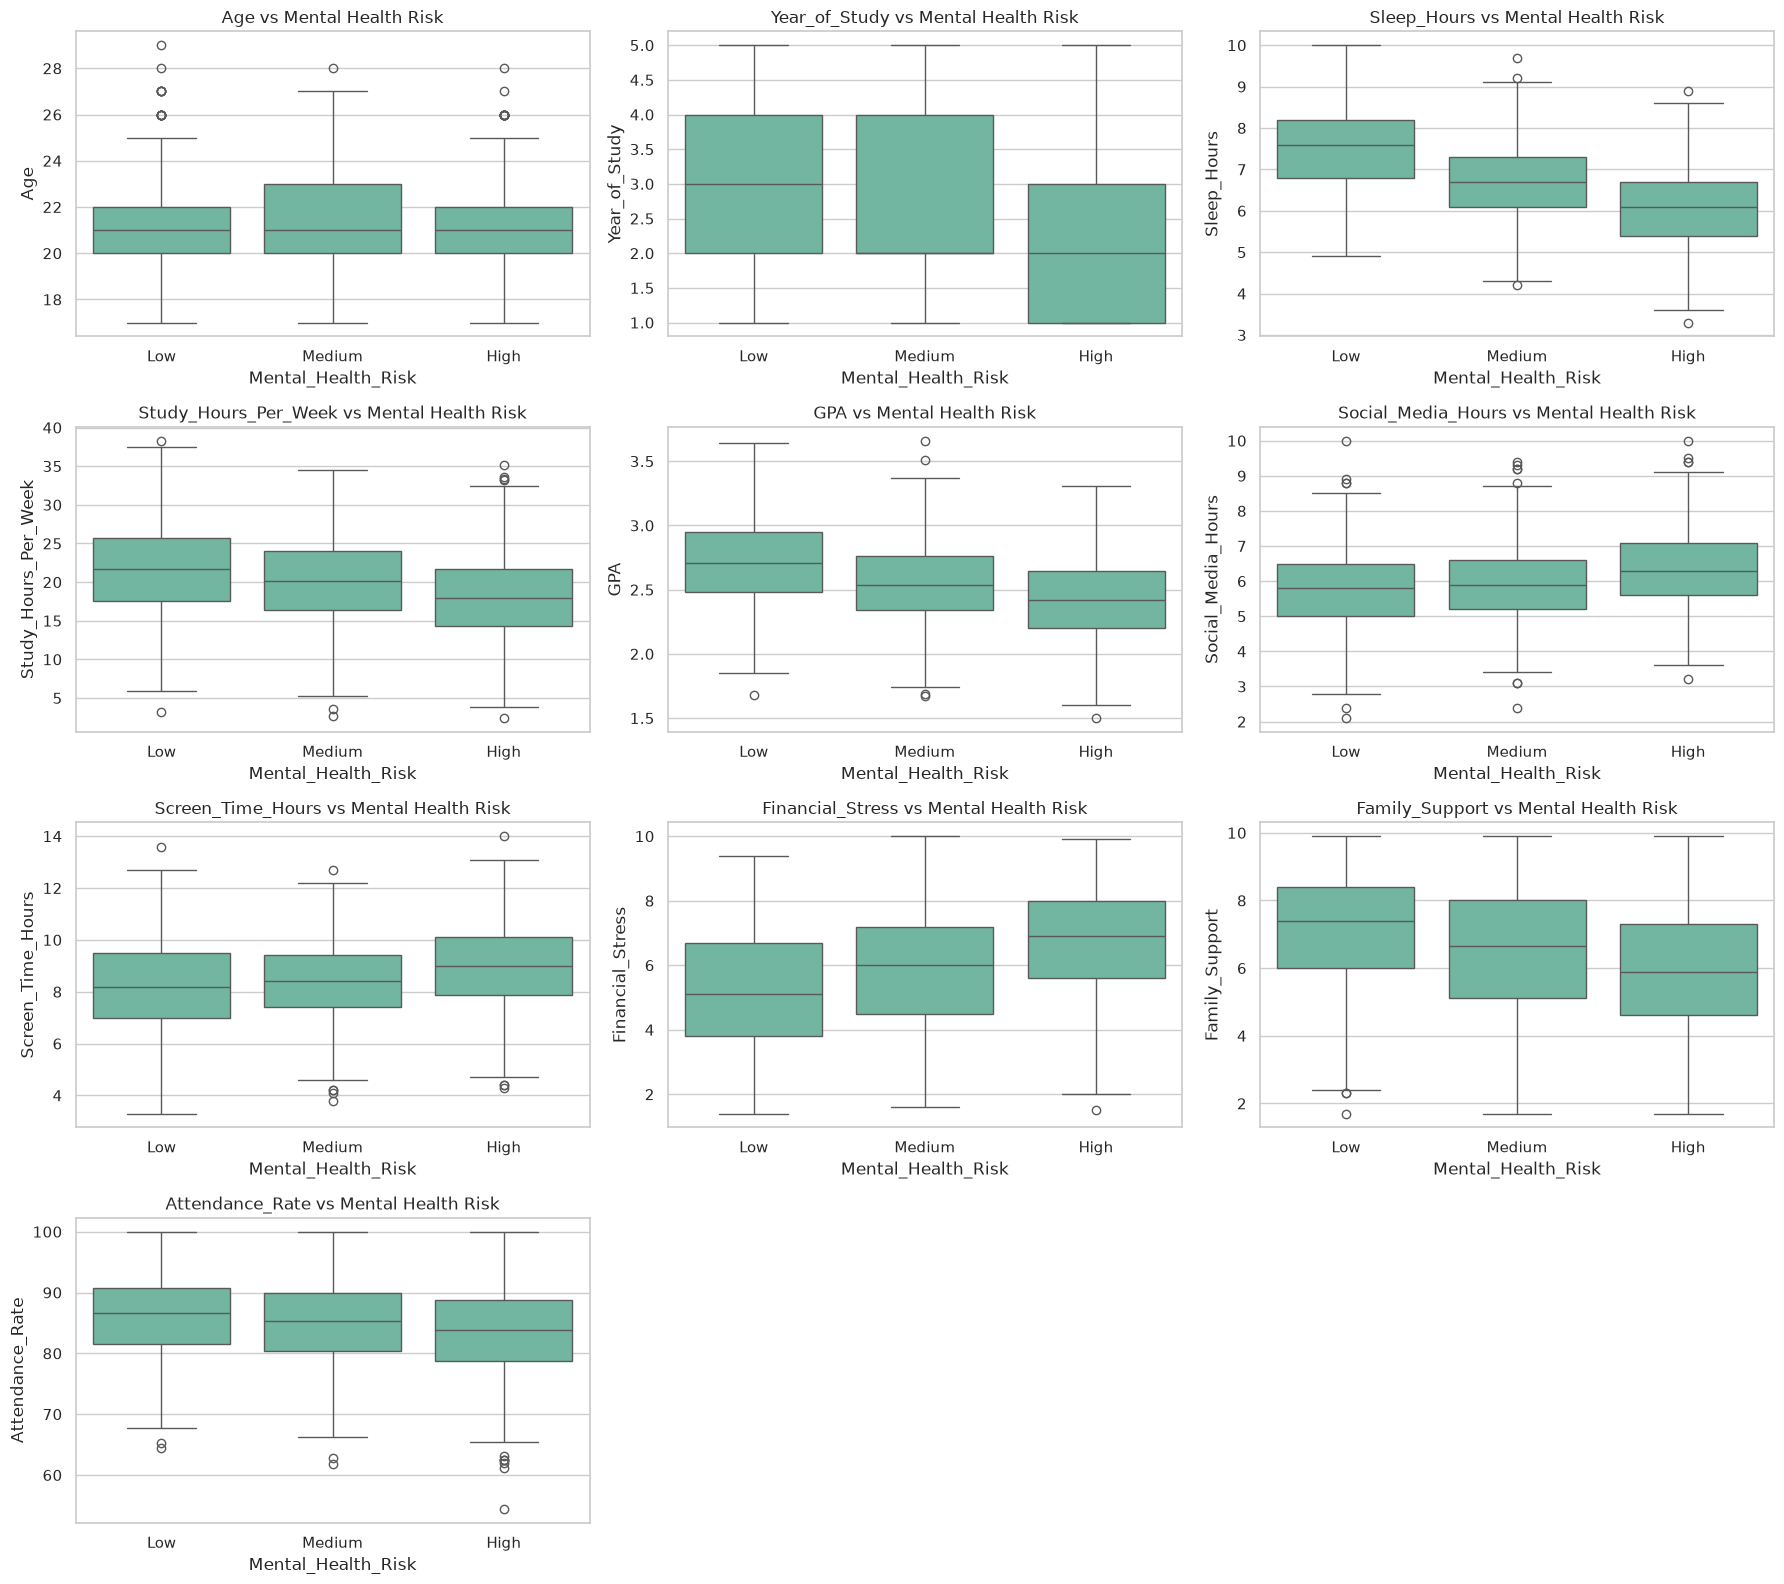

In [25]:
fig, axes = plt.subplots(
    nrows=4,
    ncols=3,
    figsize=(18, 16)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):

    sns.boxplot(
        data=df_raw,
        x="Mental_Health_Risk",
        y=col,
        order=RISK_ORDER,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Mental Health Risk")

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig(plot_path / "08_Num_VS_Target.png")
plt.show()

# 13. Correlation Matrix & Feature Association Findings

### Correlation Heatmap Analysis (`07_Correlation_Matrix.png`):
Mapping target categories (`Low`=0, `Medium`=1, `High`=2) and calculating Pearson coefficients reveals clear linear relationships:

1. **Strongest Protective Factors (Negative Correlation with Risk):**
   - **`Sleep_Hours` ($r = -0.54$):** The single strongest linear predictor in the dataset; adequate sleep strongly aligns with lower mental health risk.
   - **`GPA` ($r = -0.35$):** Higher academic performance strongly correlates with lower risk levels.
   - **`Family_Support` ($r = -0.25$):** Protective psychosocial buffer.
   - **`Study_Hours_Per_Week` ($r = -0.24$):** Consistent academic engagement associates with reduced risk.
   - **`Physical_Activity` ($r = -0.23$):** Regular exercise is negatively correlated with risk.
2. **Strongest Risk Drivers (Positive Correlation with Risk):**
   - **`Financial_Stress` ($r = +0.31$):** Major stressor associated with heightened risk.
   - **`Previous_Mental_Health_History_Yes` ($r = +0.24$):** Substantial clinical risk indicator.
   - **`Social_Media_Hours` ($r = +0.21$):** Excessive digital social consumption associates with risk.
   - **`Screen_Time_Hours` ($r = +0.17$):** Moderate positive risk correlate.
   - **`Part_Time_Job_Yes` ($r = +0.11$):** Working students experience slightly elevated risk.
3. **Neutral Features:**
   - **`Age` ($r = +0.005$)** and **`Gender` ($|r| < 0.02$)** exhibit near-zero correlation with mental health risk, indicating risk is driven by behavioral, psychosocial, and academic factors rather than demographic status.

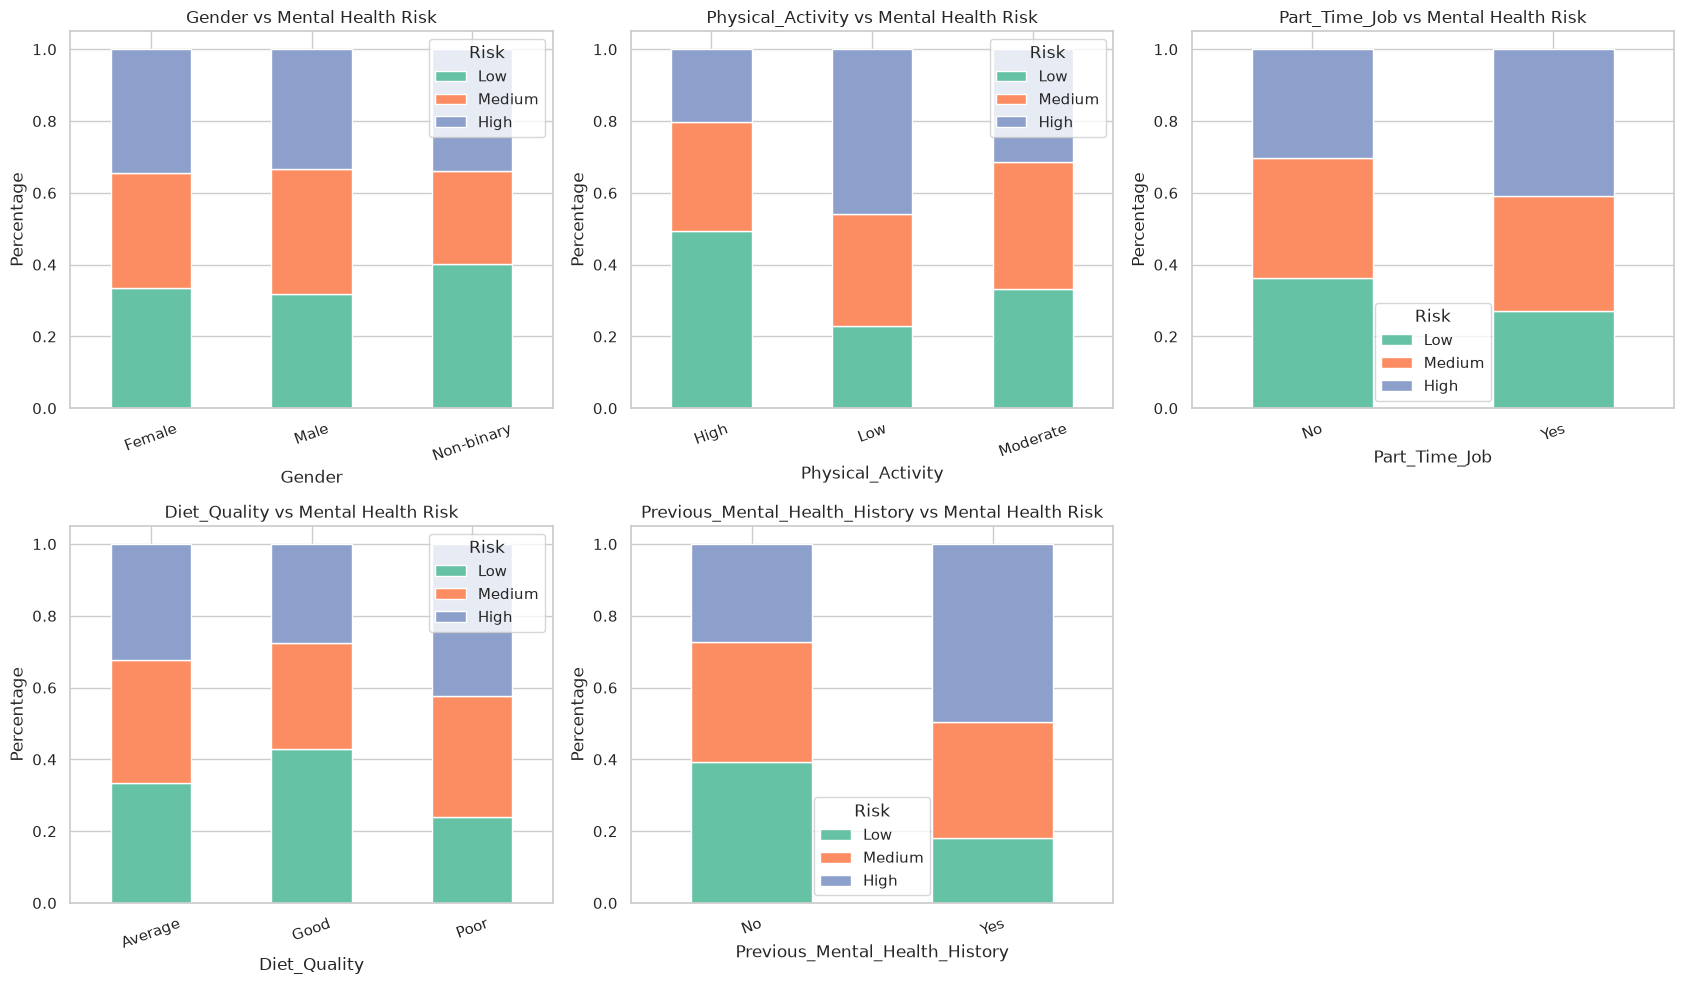

In [26]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, col in enumerate(categorical_cols):

    cross_tab = pd.crosstab(
        df_raw[col],
        df_raw["Mental_Health_Risk"],
        normalize="index"
    )

    cross_tab = cross_tab.reindex(
        columns=RISK_ORDER,
        fill_value=0
    )

    cross_tab.plot(
        kind="bar",
        stacked=True,
        ax=axes[i],
        color=sns.color_palette("Set2", 3)
    )

    axes[i].set_title(f"{col} vs Mental Health Risk")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Percentage")
    axes[i].legend(title="Risk")
    axes[i].tick_params(axis="x", rotation=20)

axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig(plot_path / "09_Cat_VS_Target.png")
plt.show()

# 14. Target Stratification: Numerical & Categorical Risk Profiling

### Numerical Boxplots vs. Target (`08_Num_VS_Target.png`):
- Monotonic shifts across Low → Medium → High tiers:
  - Median sleep drops stepwise from ~7.5h (Low) to ~6.7h (Medium) to ~6.0h (High).
  - Median GPA drops progressively from ~2.72 to ~2.55 to ~2.42.
  - Median Financial Stress escalates from ~5.2 to ~5.9 to ~6.7.

---

### Categorical Cross-Tabulations (`09_Cat_VS_Target.png`):
- **Prior History:** Students with prior mental health history show nearly **50% High Risk** prevalence versus only ~27% among students without prior history.
- **Physical Activity:** High physical activity cohorts display the lowest High Risk share (~18%), whereas Low activity groups exceed 40% High Risk.
- **Diet Quality:** Poor diet quality correlates with an inflated High Risk proportion compared to Good diet.
- **Gender & Part-Time Job:** Gender categories show virtually identical 33% risk distributions; part-time workers show a minor increase in High Risk incidence.

In [27]:
risk_summary = (
    df_raw
    .groupby("Mental_Health_Risk")[numeric_cols]
    .mean()
    .T
)

display(risk_summary.round(2))

Mental_Health_Risk,High,Low,Medium
Age,21.14,21.11,21.14
Year_of_Study,2.36,2.90,2.64
Sleep_Hours,6.04,7.52,6.73
Study_Hours_Per_Week,18.36,21.70,19.98
GPA,2.42,2.72,2.55
Social_Media_Hours,6.35,5.76,5.92
Screen_Time_Hours,8.96,8.26,8.42
Financial_Stress,6.69,5.24,5.90
Family_Support,5.96,7.09,6.53
Attendance_Rate,83.77,86.33,85.19


# 15. Quantitative Group Means by Risk Tier

### Mean Values Comparison Table (`risk_summary`):
| Feature | Low Risk Mean | Medium Risk Mean | High Risk Mean | Total Spread (Δ) | Trend |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Sleep_Hours** | **7.52 h** | 6.73 h | **6.04 h** | -1.48 h | Strong Decrease |
| **GPA** | **2.72** | 2.55 | **2.42** | -0.30 | Clear Decrease |
| **Study_Hours_Per_Week** | **21.70 h** | 19.98 h | **18.36 h** | -3.34 h | Moderate Decrease |
| **Family_Support** | **7.09** | 6.53 | **5.96** | -1.13 | Moderate Decrease |
| **Attendance_Rate** | **86.33%** | 85.19% | **83.77%** | -2.56% | Slight Decrease |
| **Financial_Stress** | **5.24** | 5.90 | **6.69** | +1.45 | Strong Increase |
| **Social_Media_Hours** | **5.76 h** | 5.92 h | **6.35 h** | +0.59 h | Moderate Increase |
| **Screen_Time_Hours** | **8.26 h** | 8.42 h | **8.96 h** | +0.70 h | Moderate Increase |
| **Year_of_Study** | 2.90 | 2.64 | 2.36 | -0.54 | Slight Decrease |
| **Age** | 21.11 | 21.14 | 21.14 | +0.03 | Neutral |

In [31]:
df_check = df_raw.copy()

df_check["invalid_social_screen"] = (
    df_check["Social_Media_Hours"] >
    df_check["Screen_Time_Hours"]
)

df_check["Daily_Study_Hours"] = (
    df_check["Study_Hours_Per_Week"] / 7
)

df_check["Daily_Total_Hours"] = (
    df_check["Daily_Study_Hours"]
    + df_check["Sleep_Hours"]
    + df_check["Social_Media_Hours"]
)

df_check["invalid_daily_total"] = (
    df_check["Daily_Total_Hours"] > 24
)

validation_cols = [
    col for col in df_check.columns
    if col.startswith("invalid_")
]

validation_summary = pd.DataFrame({
    "Invalid_Count": df_check[validation_cols].sum(),
    "Invalid_Percentage": (
        df_check[validation_cols].mean() * 100
    ).round(2)
})

display(validation_summary)

,Invalid_Count,Invalid_Percentage
invalid_social_screen,37,1.85
invalid_daily_total,0,0.00


# 16. Cross-Feature Consistency Checks & Comprehensive EDA Conclusions

### Logical Consistency Findings (`df_check`):
1. **Daily Time Budget Check:**
   - Evaluated: $(\text{Study Hours} / 7) + \text{Sleep Hours} + \text{Social Media Hours} > 24$.
   - Result: **0 violations (0.00%)**. All records adhere to daily 24-hour physical time constraints.
2. **Social Media vs. Screen Time Check:**
   - Evaluated: $\text{Social Media Hours} > \text{Screen Time Hours}$.
   - Result: **37 violations (1.85%)**. A small subset of students reported social media hours exceeding total screen time (likely reflecting multi-device usage or interpreting screen time strictly as non-mobile screen time).

---

### Comprehensive Synthesis:
The EDA validates that the dataset is structurally sound, highly predictive, and free from catastrophic corruption:
- **Balanced Target:** The 33/33/34% distribution guarantees unbiased model training.
- **Predictive Variance:** Pronounced separation exists across sleep, academic performance, financial strain, and family support.
- **Non-Causality Principle:** All findings reflect observational associations suitable for statistical risk stratification, not clinical diagnoses.

# 17. Actionable Preprocessing Roadmap (Handoff to Phase 02)

To ensure seamless progression to **Phase 02 (Data Cleaning & Feature Engineering)**, the following exact preprocessing protocol has been established from this audit:

| Priority | Issue / Step | Target Features | Recommended Preprocessing Action |
| :---: | :--- | :--- | :--- |
| **1** | **Primary Key Exclusion** | `Student_ID` | Drop column from feature matrix $\mathbf{X}$ to prevent spurious memorization. |
| **2** | **Logical Discrepancy** | `Social_Media_Hours`, `Screen_Time_Hours` | For the 37 inconsistent rows, cap `Social_Media_Hours` to equal `Screen_Time_Hours` or compute combined digital engagement index. |
| **3** | **Missing Value Imputation** | 6 Numerical Features (350 cells) | Apply median imputation conditioned on `Year_of_Study` or overall median to avoid distortion from outliers. |
| **4** | **Categorical Imputation** | `Diet_Quality` (69 cells) | Impute using mode ('Average') or encode as separate 'Missing' level. |
| **5** | **Outlier Handling** | 61 IQR Outliers (`Sleep_Hours`, `Age`, `Attendance_Rate`) | Apply Winsorization (1st and 99th percentiles) or robust quantile scaling (`RobustScaler`) rather than deleting rows. |
| **6** | **Categorical Encoding** | `Gender`, `Part_Time_Job`, `Previous_Mental_Health_History` | Apply One-Hot Encoding (`drop_first=True` or `handle_unknown='ignore'`). |
| **7** | **Ordinal Encoding** | `Physical_Activity`, `Diet_Quality` | Map to ordered integer scales: Low/Poor=0, Moderate/Average=1, High/Good=2. |
| **8** | **Feature Scaling** | All Numerical Features | Fit `StandardScaler` or `RobustScaler` on training split only to prevent data leakage. |
| **9** | **Data Splitting** | Entire Dataset ($N = 2,000$) | Perform stratified train-test split (80/20 or 70/15/15) preserving the 1:1:1 risk distribution. |